# INFO 2950 Project: Phase 2
Troy Goetz (tmg85) and Nicholas Grabowski (nrg39)

**Chess openings and player ratings**

## RESEARCH QUESTION

We want to know whether the openings that work well at one rating level also work well at another. A player's rating matters, but so does the rating of the opponent. An opening with a high score might simply have been used by stronger players against weaker opponents. We compare the same opening families across rating groups and plan to account for that rating gap in our later models.

**Question:** Do some chess openings perform better at different player ratings, even after accounting for the rating gap between opponents?

We use “perform better” to mean a higher average score for White: one point for a win, half a point for a draw, and zero for a loss. This keeps the outcome consistent across games. For example, a low White score in Sicilian games means Black scored well in those games; it does not mean the Sicilian is bad for both players.

## DATA COLLECTION AND CLEANING

We collected game records from Chess.com's public API. We used the public list of recently active accounts that identified their country as the United States, shuffled the usernames with seed 2950, and selected 300 accounts. We then downloaded each selected account's available archives for July, August, and September 2026. Their opponents could be from any country. The saved archive log records 900 successful monthly requests.

The download contained 64,738 rows. We kept the original CSV and the account-list snapshot so our work can be checked without contacting the API again. The collection notebook is separate; the cells below show the cleaning, grouping, and sampling that turn those records into our analysis dataset.

**Sources and files:** [API documentation](https://www.chess.com/news/view/published-data-api), [raw CSV archive](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/raw/chess_games_raw.csv.gz), [collection records](https://github.com/Toyman123/info2950-project/tree/main/phase2/data/raw), and [opening-label lookup](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/opening_lookup.csv).

### Set up the notebook

We use pandas to read and save tables, DuckDB to filter and summarize them with SQL, and Seaborn to draw the plots. Matplotlib controls titles, axis labels, and spacing. The next cell installs DuckDB if it is missing from the Colab environment.

In [1]:
%pip install -q duckdb seaborn==0.13.2

Execution environment: DuckDB 1.5.6; Seaborn 0.13.2.


In [2]:
# Import the packages used in class and choose one plotting style.
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
pd.set_option("display.max_columns", 10)
pd.set_option("display.float_format", "{:.2f}".format)

rating_groups = ["Under 1000", "1000–1499", "1500–1999", "2000+"]
rating_colors = ["#33658A", "#D17A22", "#3A8067", "#865D91"]

### Read the source data

The raw CSV includes the full PGN record for each game, which makes it large. PGN is a text format containing game information and moves. The archive is compressed without dropping any rows or columns. We show a few useful columns below instead of printing long move records and URLs across the page.

In [3]:
# Read the archived source tables. pandas decompresses the .gz file.
games = pd.read_csv("https://raw.githubusercontent.com/Toyman123/info2950-project/main/phase2/data/raw/chess_games_raw.csv.gz")
opening_lookup = pd.read_csv("https://raw.githubusercontent.com/Toyman123/info2950-project/main/phase2/data/opening_lookup.csv")

# Save row order so changing to SQL does not change our existing sample.
games["source_order"] = range(len(games))
audit = [("Original downloaded rows", len(games))]

preview = duckdb.sql("""
    SELECT white_rating, black_rating, time_class,
           time_control, white_result
    FROM games
    ORDER BY source_order
    LIMIT 5
""").df()
display(preview)

white_rating,black_rating,time_class,time_control,white_result
1345,1339,blitz,300,win
1331,1343,blitz,300,checkmated
1323,1355,blitz,300,resigned
1362,1316,blitz,300,win
1309,1369,blitz,300,abandoned


### Keep the games that match our question

We keep rated blitz games played under standard chess rules. Blitz is a fast time category; the sample contains three-minute, five-minute, and three-minute-plus-two-second games. We do not combine blitz with bullet, rapid, or chess variants. A game needs a nonblank URL because that URL is how we identify repeated copies of the same game.

In [4]:
# Use SQL WHERE conditions to keep rated standard blitz games.
rated_games = duckdb.sql("""
    SELECT *
    FROM games
    WHERE rated = TRUE AND rules = 'chess' AND time_class = 'blitz'
    ORDER BY source_order
""").df()
audit.append(("Rated standard blitz games", len(rated_games)))

valid_urls = duckdb.sql("""
    SELECT * FROM rated_games
    WHERE game_url IS NOT NULL AND TRIM(game_url) <> ''
    ORDER BY source_order
""").df()
audit.append(("With a nonblank game URL", len(valid_urls)))

# A game can be downloaded through either opponent's archive.
unique_games = valid_urls.drop_duplicates(subset="game_url").copy()
audit.append(("Unique game URLs", len(unique_games)))

### Check ratings and create rating groups

We convert both rating columns to numbers and remove missing or nonpositive ratings. A positive rating gap means White was higher rated; a negative gap means Black was higher rated. For example, White rated 1400 against Black rated 1300 gives a gap of +100.

Our four groups use White's rating at the time of the game. The boundaries are under 1000, 1000–1499, 1500–1999, and 2000 or higher. These are comparison groups we chose, not official skill titles.

In [5]:
# Invalid text becomes missing, so the SQL filter can exclude it.
for column in ["white_rating", "black_rating"]:
    unique_games[column] = pd.to_numeric(
        unique_games[column], errors="coerce"
    )

base = duckdb.sql("""
    SELECT *, white_rating - black_rating AS rating_difference,
           CASE
               WHEN white_rating < 1000 THEN 'Under 1000'
               WHEN white_rating < 1500 THEN '1000–1499'
               WHEN white_rating < 2000 THEN '1500–1999'
               ELSE '2000+'
           END AS rating_group
    FROM unique_games
    WHERE white_rating > 0 AND black_rating > 0
    ORDER BY source_order
""").df()
audit.append(("With valid ratings for both players", len(base)))

### Group openings and record the result

An opening is the sequence of moves at the start of a chess game. An opening family groups related variations under one name. For instance, Alapin and Closed Sicilian labels are grouped with Sicilian. We use Chess.com's opening URLs to make these groups; we do not infer aggression or identify openings by independently replaying the moves.

The lookup file gives every observed opening URL one family label. Its rules keep a name through its first family term, such as “Defense,” “Opening,” or “Gambit,” and combine the documented alternate labels. Giuoco Piano and Pianissimo join Italian; shortened King's Indian and King's Fianchetto labels join their full families; Owens joins Owen's Defense; Magnus Queen's Gambit joins Queen's Gambit. Nimzo-Indian and Bogo-Indian labels keep their family names. “Undefined” is marked “Unknown.” The lookup is a classification of our existing source, not a second independent dataset.

We use a SQL LEFT JOIN to attach these labels without losing a game whose opening is missing. We also read the result from the PGN header and assign White a score. The source result codes include reasons such as resignation or checkmate; the PGN result gives the same win/draw/loss outcome in a consistent form.

In [6]:
# Extract the final result recorded in the PGN header.
base["game_result"] = base["pgn"].str.extract(
    r'\[Result "([^\"]+)"\]', expand=False
)

# Join one family per URL and convert completed results to White scores.
prepared = duckdb.sql("""
    SELECT b.*, COALESCE(o.opening_family, 'Unknown') AS opening_family,
           CASE b.game_result
               WHEN '1-0' THEN 1.0
               WHEN '1/2-1/2' THEN 0.5
               WHEN '0-1' THEN 0.0
           END AS white_score
    FROM base AS b
    LEFT JOIN opening_lookup AS o ON b.opening_url = o.opening_url
    WHERE b.game_result IN ('1-0', '1/2-1/2', '0-1')
    ORDER BY b.source_order
""").df()
audit.append(("With a recognized completed result", len(prepared)))

# Display the cleaning record and save an intermediate file.
cleaning_record = pd.DataFrame(
    audit, columns=["Cleaning step", "Rows remaining"]
)
display(cleaning_record)
prepared.drop(columns="source_order").to_csv(
    "chess_games_prepared.csv", index=False
)

Cleaning step,Rows remaining
Original downloaded rows,64738
Rated standard blitz games,29385
With a nonblank game URL,29385
Unique game URLs,29385
With valid ratings for both players,29385
With a recognized completed result,29385


The filters leave 29,385 games. Checking URLs, duplicate games, ratings, and results did not remove additional rows from this particular download. We show those checks because they are part of the procedure, even when they remove zero games.

### Keep the same 600-game sample

We selected 150 games at random from each rating group with seed 2950. That gives us 600 games without letting the much larger under-1000 group dominate the comparison. We keep the same game selection used for peer review; changing the code to SQL and updating the presentation does not create a new sample. We use pandas for this sampling step and SQL for the summaries below.

In [7]:
# Select the same 150 games from each group, using the original row order.
samples = []
for group in rating_groups:
    group_games = prepared[prepared["rating_group"] == group]
    if len(group_games) < 150:
        raise ValueError("A rating group has fewer than 150 games.")
    samples.append(group_games.sample(n=150, random_state=2950))

analysis_games = pd.concat(samples, ignore_index=True)
analysis_games = analysis_games.sample(
    frac=1, random_state=2950
).reset_index(drop=True)
analysis_games = analysis_games.drop(columns="source_order")

# Save the analysis-ready data, then check the sample size with SQL.
analysis_games.to_csv("chess_analysis_600.csv", index=False)
sample_check = duckdb.sql("""
    SELECT rating_group AS "White rating group", COUNT(*) AS "Games",
           COUNT(DISTINCT game_url) AS "Unique games",
           COUNT(DISTINCT sampled_player) AS "Archive accounts"
    FROM analysis_games
    GROUP BY rating_group
""").df()
sample_check = sample_check.set_index("White rating group").reindex(
    rating_groups
).reset_index()
display(sample_check)

White rating group,Games,Unique games,Archive accounts
Under 1000,150,150,45
1000–1499,150,150,10
1500–1999,150,150,3
2000+,150,150,3


## DATA DESCRIPTION

Our final dataset has 600 rows, with one unique rated standard blitz game per row. The games were played in July, August, or September 2026. Each rating group contains 150 games. There are 46 identified opening families and two games with undefined opening labels. Those two games stay in the dataset, but we leave them out of comparisons between named opening families.

### What does “rating” mean?

A rating is a numerical estimate of a player's strength relative to other players in that rating pool. Higher ratings generally indicate stronger performance. Players often call the number “Elo,” but [Chess.com uses a Glicko rating system](https://support.chess.com/en/articles/8566476-how-do-ratings-work-on-chess-com). We use the blitz rating recorded for each player when the game was played. It is not a measure of intelligence, a fixed ability level, or a rating that can be compared directly with every other chess platform.

### What does every column mean?

The final CSV retains the source fields so a reviewer can trace a game back to the collection. The added fields are listed separately below. Temporary tables and the `source_order` helper are not part of the final CSV.

| Source column | Meaning |
|:--|:--|
| `sampled_player` | Selected account whose archive supplied the row; not necessarily the White player. |
| `archive_month` | Month of the downloaded archive: 7, 8, or 9 for July, August, or September 2026. |
| `game_url` | Public link that identifies the game; used to remove duplicate games. |
| `white_username` | Account that played the White pieces. |
| `black_username` | Account that played the Black pieces. |
| `white_rating` | White's recorded blitz rating at the time of the game. |
| `black_rating` | Black's recorded blitz rating at the time of the game. |
| `white_result` | Chess.com's result code for White, such as `win`, `resigned`, or `checkmated`. |
| `black_result` | Corresponding result code for Black. |
| `rated` | Whether the game counted toward ratings; always True in the final sample. |
| `rules` | Chess variant; always `chess`, meaning standard chess, after filtering. |
| `time_class` | Broad speed category; always `blitz` after filtering. |
| `time_control` | Starting seconds and any increment. `180` is three minutes, `300` is five minutes, and `180+2` adds two seconds after each move. |
| `end_time` | Game-ending time as seconds since January 1, 1970, UTC; a timestamp rather than a duration. |
| `opening_url` | Chess.com's public label/link for the recorded opening variation. |
| `pgn` | Portable Game Notation: text containing game headers and recorded moves. |

| Added column | Meaning |
|:--|:--|
| `rating_group` | Group based on White's rating: under 1000, 1000–1499, 1500–1999, or 2000+. |
| `rating_difference` | White's rating minus Black's rating, in rating points. |
| `opening_family` | Our broader grouping of related opening labels; “Unknown” means the source label was undefined or missing. |
| `game_result` | Completed result from the PGN: `1-0` means White won, `0-1` means Black won, and `1/2-1/2` means a draw. |
| `white_score` | Numerical outcome from White's perspective: 1, 0, or 0.5, respectively. Its average is a score rate, not a win percentage. |

### Why does this dataset exist, and how did we make our version?

Chess.com records games as part of running its platform and provides public records through its API. We assembled our version to compare opening results across rating groups. We downloaded the archives with Python, kept the raw records, filtered them, added the opening labels and score, and selected our sample. The cells above document those steps. We used DuckDB for SQL queries and pandas for file handling and reproducible sampling.

### What affected which games were included?

An account had to appear in the public US-listed account snapshot and be selected for collection. It also needed available games during the three months. More active sampled accounts contributed more games to the original pool. Country is self-reported and does not establish residency; opponents may be from elsewhere. The four groups were balanced by our sampling decision, not by Chess.com's population distribution.

### Did players know about this use?

We used public records and did not contact players. We do not know whether they expected their game histories to be used for a class project. We report patterns for groups rather than rank individual accounts.

### Where are the files?

- [Original raw CSV, compressed without dropping data](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/raw/chess_games_raw.csv.gz)
- [Player-list snapshot, selected players, and archive log](https://github.com/Toyman123/info2950-project/tree/main/phase2/data/raw)
- [Opening-label lookup](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/opening_lookup.csv)
- [Final 600-game analysis CSV](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/chess_analysis_600.csv)
- [Project instructions and collection notebook](https://github.com/Toyman123/info2950-project/blob/main/phase2/README.md)

## DATA LIMITATIONS

**Who we sampled.** These are games collected through recently active US-listed accounts, not a random sample of all Chess.com games. Less active accounts and games involving only accounts outside that list may be missed. More active sampled accounts contributed more games, so their opening habits can influence the sample.

**What the rating groups mean.** We chose equal numbers in four groups to compare rating levels. Overall percentages from these 600 games do not estimate platform-wide percentages. A group describes White's rating, and the opponent may have a different rating. Ratings themselves are estimates and may be uncertain.

**Small opening groups.** Having 150 games per rating group does not give us 150 games for every opening. Some opening-by-rating groups have only a few games. We show their counts and do not draw strong conclusions from extreme averages based on very small samples. Our display rule of at least 10 games is not a guarantee that an estimate is reliable.

**How openings are labeled.** We group Chess.com's URL labels rather than reconstruct board positions. Different move orders can reach similar positions, and a broad family can contain variations with different plans. Our documented lookup makes the grouping reproducible, but it is not a definitive classification of chess. Two undefined labels remain unknown. We do not label families as aggressive or defensive because we have not measured those traits.

**Repeated players and other influences.** Players can appear in more than one game, so the observations are not fully independent. Only three sampled archive accounts supplied the selected games in each of the two highest rating groups, although their opponents include many more accounts. One sampled archive account supplies 138 of all 600 games (23%). This concentration means a few players' habits can strongly affect the opening comparisons. The “Archive accounts” column in our sample check counts source accounts, not all players in the games. Familiarity with an opening, preparation, account history, and playing style are not recorded in our analysis. Adjusting for rating gaps cannot remove all of those influences. We can describe associations, not claim that choosing an opening causes a win.

**Scope and unusual games.** We use three months of blitz data. Three-minute, five-minute, and increment games can play differently, and our findings may not extend to other speeds or periods. We retain large rating gaps unless there is evidence of a recording error; deleting inconvenient games after seeing results would change the sample. A higher White score also does not mean an opening benefits both colors.

**People represented in the records.** Usernames and game links can identify accounts. We report aggregate results and avoid ranking players or treating unusual outcomes as evidence of cheating. Small samples could otherwise lead readers to unfair judgments about individual players or lower-rated groups. The original public identifiers remain available for checking the source, so public availability should not be confused with anonymity.

## EXPLORATORY DATA ANALYSIS

We first check the ratings and rating gaps, then look at which opening families are represented. Finally, we compare White's score for common openings. SQL produces the summary tables, and Seaborn draws the figures. These are descriptive checks; we have not fitted either preregistered regression.

### Ratings and the gap between opponents

The next table puts the variables on separate rows and names each statistic. This makes it easier to read than the default `describe()` output. Count is the number of games with a recorded value, and standard deviation describes how spread out the values are.

In [8]:
# Calculate the same statistics for each rating variable using SQL.
stats_parts = []
for column, label in [
    ("white_rating", "White rating"),
    ("black_rating", "Black rating"),
    ("rating_difference", "White minus Black")
]:
    row = duckdb.sql(f"""
        SELECT '{label}' AS "Variable", COUNT({column}) AS "Games",
               ROUND(AVG({column}), 2) AS "Mean",
               ROUND(MEDIAN({column}), 2) AS "Median",
               MIN({column}) AS "Minimum", MAX({column}) AS "Maximum",
               ROUND(STDDEV_SAMP({column}), 2) AS "Std. deviation"
        FROM analysis_games
    """).df()
    stats_parts.append(row)
stats_table = pd.concat(stats_parts, ignore_index=True)
display(stats_table)

Variable,Games,Mean,Median,Minimum,Maximum,Std. deviation
White rating,600,1450.54,1500.00,101,3057,657.97
Black rating,600,1438.20,1455.50,137,2739,654.76
White minus Black,600,12.35,3.00,-522,1715,134.04


The mean rating is 1450.54 for White and 1438.20 for Black. White's mean advantage is 12.35 points, while the median gap is just 3 points. The middle half of game-level gaps runs from -18.25 to +27 points. Most opponents were therefore closely matched, even though a few gaps were much larger. These are differences calculated within each game; subtracting the two separate median ratings would not give the median game-level gap.

The full-range histogram below keeps the unusual games visible. The second panel zooms in on gaps from -150 to +150 without removing those games from the dataset. We use fixed-width bins and label both views so the zoom does not hide the existence of the outliers.

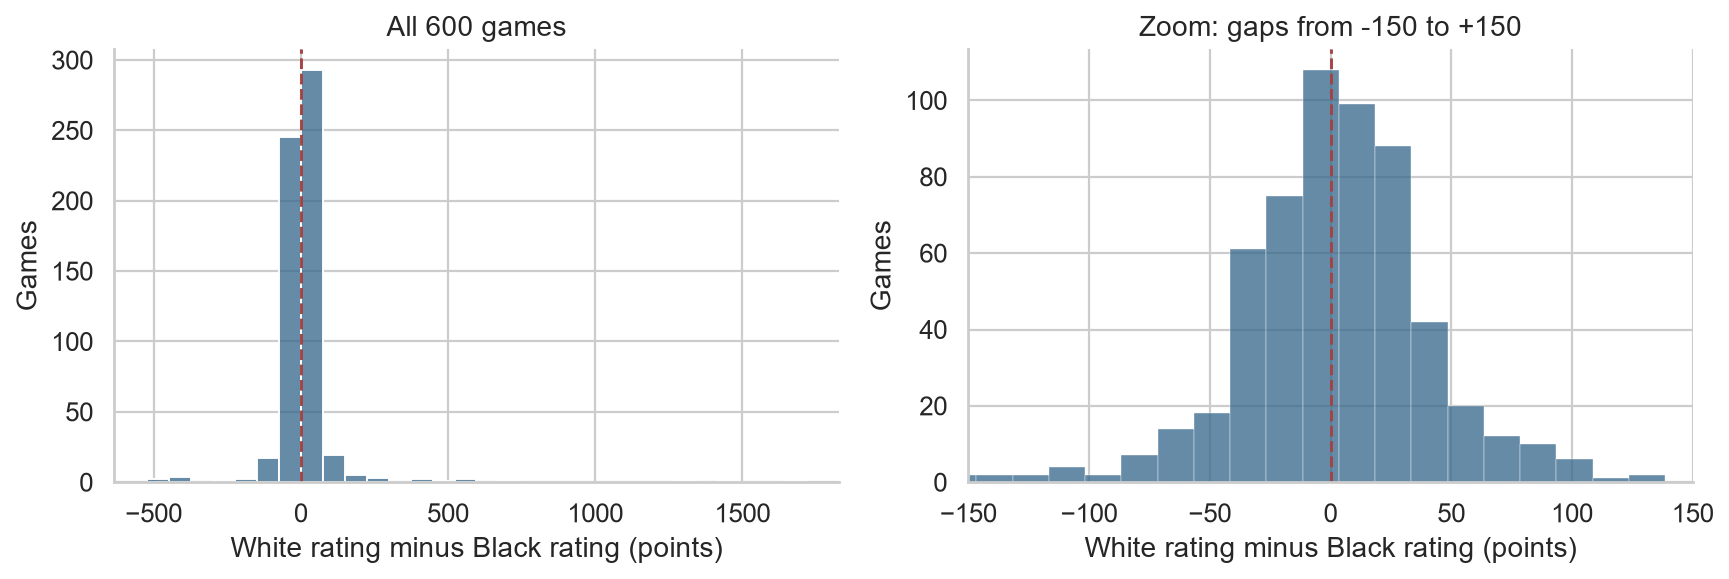

In [9]:
# Use Seaborn histograms for the full range and a clearly labeled zoom.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=analysis_games, x="rating_difference", bins=30,
             color="#33658A", ax=axes[0])
sns.histplot(data=analysis_games, x="rating_difference", binwidth=15,
             color="#33658A", ax=axes[1])
axes[0].set_title("All 600 games")
axes[1].set_title("Zoom: gaps from -150 to +150")
axes[1].set_xlim(-150, 150)
for ax in axes:
    ax.axvline(0, color="#A34343", linestyle="--", linewidth=1.3)
    ax.set_xlabel("White rating minus Black rating (points)")
    ax.set_ylabel("Games")
sns.despine()
plt.tight_layout()
plt.show()

The largest gap is +1715 points, so we checked its source fields rather than automatically removing it. The next SQL query displays the extreme game. Both ratings are positive and the gap matches their subtraction; that establishes an internally consistent record, not whether the matchmaking was typical or either rating was well established.

In [10]:
# Inspect the largest gap without running a hypothesis test.
largest_gap = duckdb.sql("""
    SELECT white_rating AS "White rating", black_rating AS "Black rating",
           rating_difference AS "Gap", game_result AS "Result",
           time_control AS "Time control"
    FROM analysis_games
    ORDER BY ABS(rating_difference) DESC
    LIMIT 1
""").df()
display(largest_gap)

White rating,Black rating,Gap,Result,Time control
2000,285,1715,1-0,180


### Opening coverage across rating groups

We choose the eight most frequent identified families by total count, before comparing their scores. Less common families stay in the CSV and the full opening-count file. The table gives the actual sample size behind each opening/rating comparison. A zero means that no game in that combination was selected.

In [11]:
# GROUP BY counts every identified family; ORDER BY chooses the display order.
family_totals = duckdb.sql("""
    SELECT opening_family, COUNT(*) AS games
    FROM analysis_games
    WHERE opening_family <> 'Unknown'
    GROUP BY opening_family
    ORDER BY games DESC, opening_family
""").df()
top_families = family_totals.head(8)["opening_family"].tolist()

coverage_long = duckdb.sql("""
    SELECT opening_family, rating_group, COUNT(*) AS games
    FROM analysis_games
    WHERE opening_family <> 'Unknown'
    GROUP BY opening_family, rating_group
""").df()
coverage = coverage_long.pivot(
    index="opening_family", columns="rating_group", values="games"
).reindex(index=top_families, columns=rating_groups).fillna(0).astype(int)
coverage.index.name = "Opening family"
coverage.columns.name = None
display(coverage)
family_totals.to_csv("all_opening_counts.csv", index=False)

,Under 1000,1000–1499,1500–1999,2000+
Opening family,,,,
Sicilian,4,15,41,32
Queen's Pawn Opening,25,12,4,3
Alekhine's Defense,0,0,0,37
French,6,14,7,7
King's Pawn Opening,11,15,6,1
Scandinavian,14,3,3,6
Bishop's Opening,5,5,11,4
Modern Defense,4,16,2,1


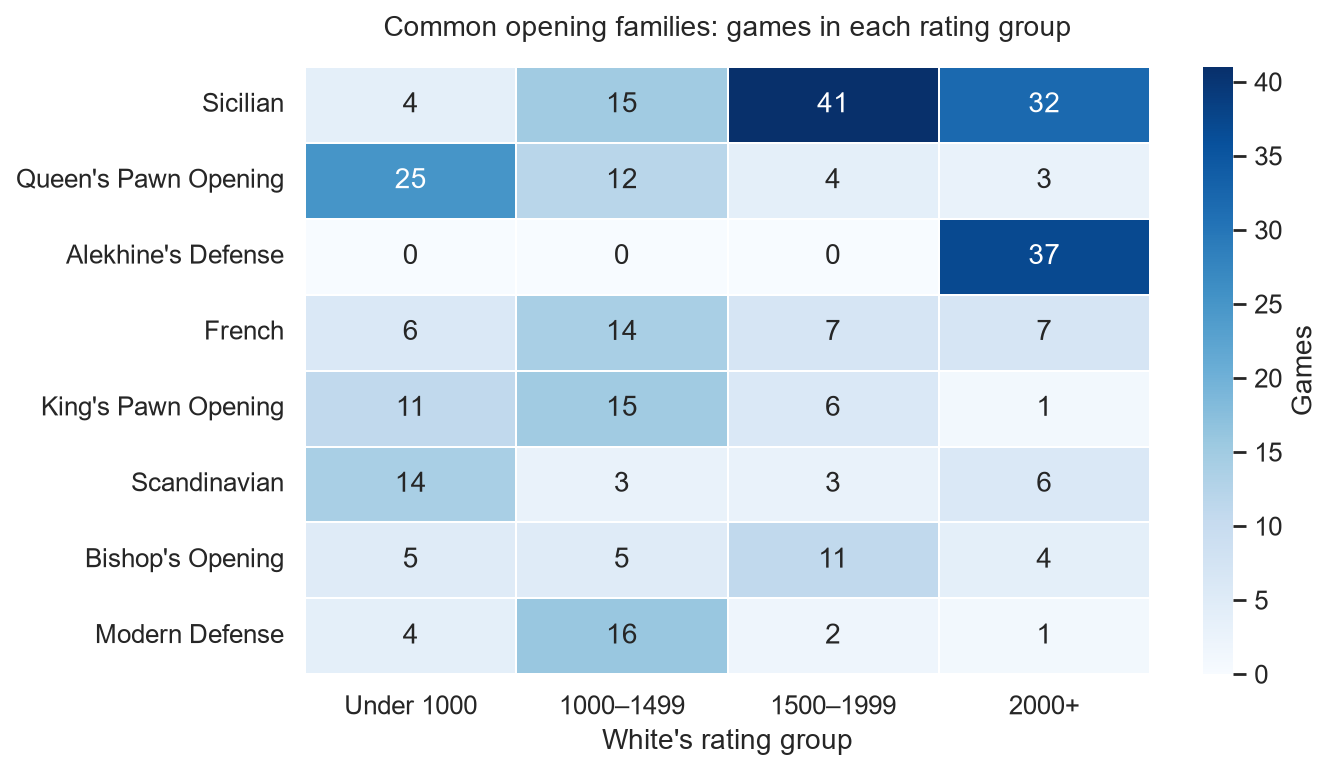

In [12]:
# A heatmap makes sparse combinations visible without 32 crowded bars.
plt.figure(figsize=(8.8, 5))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues",
            linewidths=0.7, linecolor="white",
            cbar_kws={"label": "Games"})
plt.title("Common opening families: games in each rating group", pad=14)
plt.xlabel("White's rating group")
plt.ylabel("")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Sicilian is the largest family with 92 games. It is followed by Queen's Pawn Opening (44), Alekhine's Defense (37), French (34), and King's Pawn Opening (33). The complete sample has 46 identified families and two unknown labels. Among the displayed families, the sample sizes vary a lot across rating groups. Equal totals of 150 games per group have not produced equal coverage of each opening.

King's Pawn Opening, Queen's Pawn Opening, and Sicilian each have at least 10 games in two or more rating groups. That gives us some comparisons to explore, but it still does not support conclusions about every opening at every skill level. We keep the original research question and use the count-based eligibility rules in our preregistrations to limit the later models.

### Game outcomes and opening scores

We show wins, draws, and losses first so the score is easy to interpret. An average White score of 0.50 could come from all draws or from equal numbers of wins and losses, so it should not be called a 50% win rate.

In [13]:
# Count the three outcomes in the complete 600-game sample.
outcomes = duckdb.sql("""
    SELECT CASE game_result
               WHEN '1-0' THEN 'White win'
               WHEN '0-1' THEN 'White loss'
               ELSE 'Draw'
           END AS "Outcome",
           COUNT(*) AS "Games",
           ROUND(100.0 * COUNT(*) / 600, 1) AS "Percent"
    FROM analysis_games
    GROUP BY game_result
    ORDER BY "Games" DESC
""").df()
display(outcomes)

# Calculate sample sizes and average scores with SQL aggregation.
opening_scores = duckdb.sql("""
    SELECT opening_family, rating_group, COUNT(*) AS games,
           AVG(white_score) AS average_white_score
    FROM analysis_games
    WHERE opening_family <> 'Unknown'
    GROUP BY opening_family, rating_group
""").df()
supported = opening_scores[
    opening_scores["opening_family"].isin(top_families)
    & (opening_scores["games"] >= 10)
].copy()
score_table = supported.rename(columns={
    "opening_family": "Opening family", "rating_group": "White rating group",
    "games": "Games", "average_white_score": "Average White score"
}).sort_values(["Opening family", "White rating group"])
# Show score averages to three decimal places.
pd.set_option("display.float_format", "{:.3f}".format)
display(score_table.round(3))
opening_scores.to_csv("all_opening_scores.csv", index=False)

Outcome,Games,Percent
White win,305,50.80
White loss,262,43.70
Draw,33,5.50


Opening family,White rating group,Games,Average White score
Alekhine's Defense,2000+,37,0.595
Bishop's Opening,1500–1999,11,0.500
French,1000–1499,14,0.643
King's Pawn Opening,1000–1499,15,0.467
King's Pawn Opening,Under 1000,11,0.636
Modern Defense,1000–1499,16,0.562
Queen's Pawn Opening,1000–1499,12,0.333
Queen's Pawn Opening,Under 1000,25,0.580
Scandinavian,Under 1000,14,0.321
Sicilian,1000–1499,15,0.333


The score plot uses only displayed opening/rating combinations with at least 10 games. A missing bar means the combination has fewer than 10 games, not that White never won. The table above shows the number behind every displayed average. We do not add confidence intervals here because a simple interval treating all games as independent would ignore repeated players.

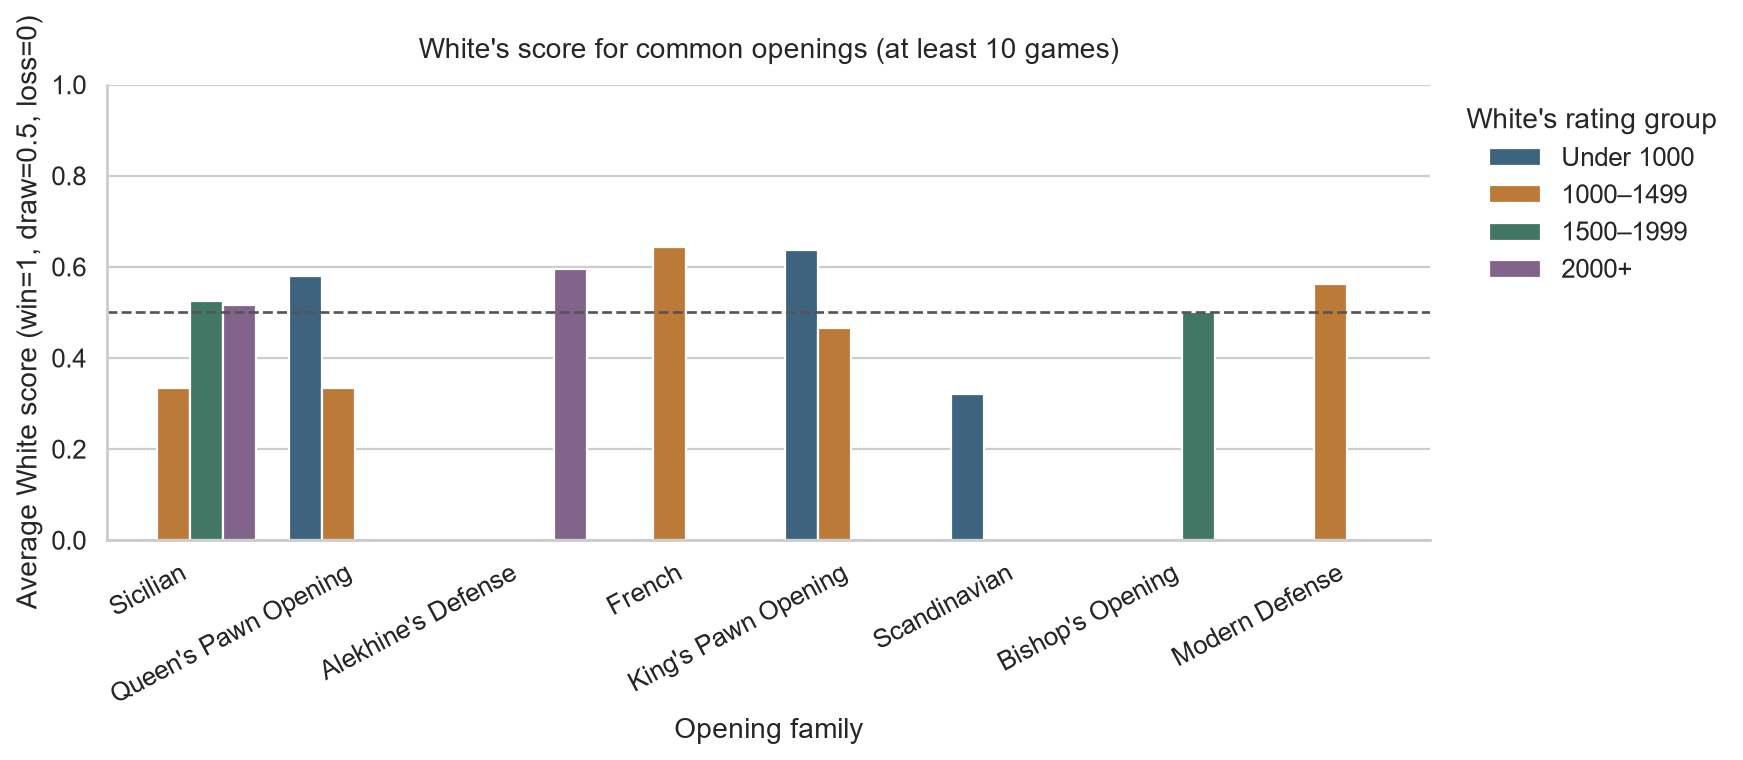

In [14]:
# Seaborn plots the SQL averages; no regression or significance test is run.
shown_families = [family for family in top_families
                  if family in supported["opening_family"].values]
plt.figure(figsize=(11, 4.8))
sns.barplot(data=supported, x="opening_family", y="average_white_score",
            hue="rating_group", order=shown_families,
            hue_order=rating_groups, palette=rating_colors, errorbar=None)
plt.axhline(0.5, color="#555555", linestyle="--", linewidth=1.2)
plt.ylim(0, 1)
plt.title("White's score for common openings (at least 10 games)", pad=12)
plt.xlabel("Opening family")
plt.ylabel("Average White score (win=1, draw=0.5, loss=0)")
plt.xticks(rotation=28, ha="right")
plt.legend(title="White's rating group", loc="upper left",
           bbox_to_anchor=(1.01, 1), frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

For Sicilian games, White's average score is 0.333 in 15 games in the 1000–1499 group and 0.524 in 41 games in the 1500–1999 group. That is a descriptive difference of about 0.19 score points. It does not yet account for opponent rating gaps, repeated players, or other differences between the games. We will not call it an opening effect or a statistically significant result from this plot alone.

The exploration changes how narrowly we can answer the question. There are many opening labels, but only a few families have enough games for useful comparisons. We therefore retain all 600 games in the data description and use only the preregistered eligible subsets for the later models. The two undefined labels are excluded only when the analysis requires a named opening. The rating gaps, sparse family groups, and varied blitz time controls remain limitations rather than reasons to silently discard games.

## QUESTIONS FOR REVIEWERS: PART 1

1. Are our opening-family groups reasonable, especially the alternate labels combined with Sicilian and Italian?
2. Is using White's rating to define groups appropriate, or would the average of both ratings be more useful?
3. Which opening/rating comparisons have enough coverage, and should we use more of the original cleaned games before the final report?
4. Should we restrict the later models to one exact blitz time control, or include time control as another predictor?
5. How should repeated players and the few very large rating gaps affect our later analysis?

## PART 2: PREREGISTRATION OF ANALYSES

Our original plans were recorded for peer review on October 15. On October 18, before fitting or testing either regression, we clarified the independence assumption and narrowed Statement 2 to opening/rating combinations with sufficient observed coverage. We chose that subset using game counts, not which opening scored better. The original plan remains in GitHub history, and this dated amendment describes the plan we will follow.

Both models will treat each game as an independent observation and use conventional regression standard errors, confidence intervals, and tests. This is a simplifying assumption, not evidence that games involving repeated players are independent. Repeated players remain a limitation. We will report both analyses regardless of their results and identify any later changes separately.

### Preregistration Statement 1

**Hypothesis:** White's expected score differs between Sicilian and French opening-family games after accounting for White's rating group and the rating gap between opponents. The hypothesis is two-sided; we do not commit to either opening having a higher White score. The purpose is to ask whether an opening-family difference remains after adjusting for measured skill, rather than simply confirming that higher-rated opponents tend to do better.

**Proposed analysis:** We will use the games labeled Sicilian or French within the fixed 600-game sample (92 Sicilian and 34 French games after the documented label grouping). We will fit a linear regression predicting White's score (win=1, draw=0.5, loss=0) from an opening indicator, categorical White rating group, and White-minus-Black rating difference divided by 100. French will be the opening reference and 1000–1499 the rating-group reference. The Sicilian coefficient is the adjusted difference in expected White score relative to French. We will assess the two-sided null hypothesis that this coefficient is zero, using a 0.05 significance threshold, and report the coefficient and 95% confidence interval regardless of the result.

We chose these recognizable families because each has at least 30 games in the sample. Their descriptive results have already been explored, but the adjusted regression and significance test have not been run. We will keep the grouping rules and sample fixed for this analysis, check residuals and predictions outside the 0–1 score range, and report limitations from sparse groups and repeated players. For fitting and inference, we will treat each game as an independent observation and use conventional regression standard errors and a 95% confidence interval. We will state that repeated players can violate this assumption and make the interval too narrow. This model is an association model, not a causal comparison.

### Preregistration Statement 2

**Hypothesis:** Among games where White is rated below 1500, the difference in White's expected score between King's Pawn Opening and Queen's Pawn Opening depends on White's rating group, after accounting for the rating gap between opponents. This is a two-sided hypothesis; we do not predict which combination will have the higher score.

**Why this subset:** The earlier plan included opening/rating combinations with very few games. Our revised comparison has observations in every cell:

| Opening family | White under 1000 | White 1000–1499 |
|:--|--:|--:|
| King's Pawn Opening | 11 | 15 |
| Queen's Pawn Opening | 25 | 12 |

These 63 games are already part of our fixed 600-game dataset. We selected the two families and two groups because all four combinations have at least 10 games, not because of their observed outcomes. That makes this a feasible small comparison, although it does not guarantee high statistical power or reliable estimates.

**Proposed analysis:** We will fit a linear regression predicting White's score (win=1, draw=0.5, loss=0) from an opening indicator, a rating-group indicator, their interaction, and the White-minus-Black rating gap divided by 100. Queen's Pawn Opening will be the opening reference and Under 1000 the rating-group reference. We will test whether the single interaction coefficient is zero using a two-sided test at a 0.05 significance threshold and report its estimate and 95% confidence interval regardless of the result. The interaction measures whether the adjusted King's-versus-Queen's Pawn score difference changes between the two rating groups.

We will treat each game as an independent observation and use conventional regression uncertainty estimates. Repeated players can violate that assumption, and small cell counts may produce wide intervals. We will check residuals and predictions outside the 0–1 score range, describe those limitations, and avoid causal claims. The conclusion will apply only to these two opening families and rating groups, not every opening or players rated 1500 and above. This regression and its significance test have not been run.

## QUESTIONS FOR REVIEWERS: PART 2

1. Is linear regression reasonable for a score that takes only 0, 0.5, and 1, and how should we report predictions outside that range?
2. Does the narrowed four-cell comparison in Statement 2 have enough coverage for the proposed interaction model?
3. How strongly might repeated players affect conclusions under our stated game-independence assumption?
4. Do the all-group Sicilian–French comparison and the below-1500 King's-versus-Queen's Pawn comparison answer useful parts of our research question?